# 03 – Modelling

Choose the features and build a sklearn pipeline that prepares the data. Imputing and scaling are learned from the training data only, so the test result stays honest.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import make_scorer


from src.config import PROCESSED, FIGURES

## Load data and target

In [ ]:
df = pd.read_csv(PROCESSED / "clean_dataset_numeric.csv")

TARGET = "short_sleep"
print(df.shape)
df[TARGET].value_counts()

(1085, 23)


short_sleep
0    833
1    252
Name: count, dtype: int64

## Columns left out of the model

In [ ]:

DROP_COLS = [
    "sleep_hours_per_night",
    "past_month_felt_rested",
    "past_month_trouble_falling_asleep",
    "past_month_trouble_staying_asleep",
    "survey_weight",
    "household_id",
]

X = df.drop(columns=DROP_COLS + [TARGET])
y = df[TARGET]
y_reg = df["sleep_hours_per_night"]   # regression target (hours)

## Feature types

In [ ]:

NUM_COLS = [
    "age",                        # years, 18-29
    "weekly_work_hours",          # hours per week
    "kids_household",             # number of children in the household
    "family_income",              # income-to-poverty ratio, ordered 1-14
    "food_security",              # 1 high ... 4 very low (ordered)
    "activity_guideline_status",  # 1 inactive ... 3 sufficiently active (ordered)
    "anxiety_frequency",          # ordered 1-5
    "depression_frequency",       # ordered 1-5
    "serious_distress",           # 1 / 2, two values (check the codebook for which is yes)
    "sex",                        # 1 male, 2 female (two values, works like yes/no)
    "housing_cost",               # 1 yes, 0 no
    "high_bloodpressure",         # 1 yes, 0 no
    "had_asthma",                 # 1 yes, 0 no
    "had_arthritis",              # 1 yes, 0 no
    "had_diabetes",               # 1 yes, 0 no
]

CAT_COLS = [
    "education_level",
]

missing = set(X.columns) - set(NUM_COLS) - set(CAT_COLS)
extra = (set(NUM_COLS) | set(CAT_COLS)) - set(X.columns)
assert not missing, f"Columns in X but not in any list: {missing}"
assert not extra, f"Columns in a list but not in X: {extra}"

## Preprocessing and `make_pipeline`

In [ ]:
num_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

cat_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocess = ColumnTransformer([
    ("num", num_pipe, NUM_COLS),
    ("cat", cat_pipe, CAT_COLS),
])


def make_pipeline(model):
    """Preprocessing + model. Each call gets its own copy of the preprocessing."""
    return Pipeline([
        ("preprocess", clone(preprocess)),
        ("model", model),
    ])

## Train/Test split

In [ ]:
X_train, X_test, y_train, y_test, y_train_reg, y_test_reg = train_test_split(
    X, y, y_reg, test_size=0.2, stratify=y, random_state=42)

print("Train:", X_train.shape, " Test:", X_test.shape)
print(f"Short sleep in train: {(y_train == 1).mean():.1%}")
print(f"Short sleep in test:  {(y_test == 1).mean():.1%}")
print(y.value_counts())

Train: (868, 16)  Test: (217, 16)
Short sleep in train: 23.3%
Short sleep in test:  23.0%
short_sleep
0    833
1    252
Name: count, dtype: int64


## Baseline

In [ ]:
from sklearn.dummy import DummyClassifier, DummyRegressor


base_clf = make_pipeline(DummyClassifier(strategy="most_frequent"))
base_clf.fit(X_train, y_train)
y_pred_base = base_clf.predict(X_test)


base_reg = make_pipeline(DummyRegressor(strategy="mean"))
base_reg.fit(X_train, y_train_reg)
y_pred_base_reg = base_reg.predict(X_test)

## Evaluation function for models

In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             mean_absolute_error, mean_squared_error, r2_score)

def evaluate_classification(name, y_true, y_pred, pos_label=1):
    row = {"model": name}
    row["accuracy"]  = accuracy_score(y_true, y_pred)
    row["precision"] = precision_score(y_true, y_pred, pos_label=pos_label, zero_division=0)
    row["recall"]    = recall_score(y_true, y_pred, pos_label=pos_label, zero_division=0)
    row["f1"]        = f1_score(y_true, y_pred, pos_label=pos_label, zero_division=0)
    return row

def evaluate_regression(name, y_true, y_pred):
    row = {"model": name}
    row["mae"]  = mean_absolute_error(y_true, y_pred)
    row["rmse"] = np.sqrt(mean_squared_error(y_true, y_pred))
    row["r2"]   = r2_score(y_true, y_pred)
    return row

### Classification model

In [ ]:

log_model = make_pipeline(LogisticRegression(max_iter=2000, class_weight="balanced"))
tree_model = make_pipeline(DecisionTreeClassifier(max_depth=5, random_state=42))
rf_model = make_pipeline(RandomForestClassifier(n_estimators=200, random_state=42))
knn_model = make_pipeline(KNeighborsClassifier(n_neighbors=15))


clf_models = {
    "Logistic Regression": log_model,
    "Decision Tree": tree_model,
    "Random Forest": rf_model,
    "k-NN": knn_model,
}

f1_short = make_scorer(f1_score, pos_label=1)

cv_rows = []
for name, model in clf_models.items():
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring=f1_short)
    cv_rows.append({"model": name, "cv_f1_mean": scores.mean(), "cv_f1_std": scores.std()})

cv_df = pd.DataFrame(cv_rows).sort_values("cv_f1_mean", ascending=False)
print(cv_df.round(3))


log_model.fit(X_train, y_train)
y_pred_lg = log_model.predict(X_test)

tree_model.fit(X_train, y_train)
y_pred_tree = tree_model.predict(X_test)

rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

knn_model.fit(X_train, y_train)
y_pred_knn = knn_model.predict(X_test)



                 model  cv_f1_mean  cv_f1_std
0  Logistic Regression       0.372      0.072
2        Random Forest       0.110      0.043
1        Decision Tree       0.073      0.041
3                 k-NN       0.025      0.032


We choce four differnet classification models to compare against the baseline, using our make_pipeline to learn from training data only.
- Logistic Regression:
We chose logistic regression as it is a simple model that gives probability.

- Decision tree:
We chose a decision tre because it is simple, readable yes/no.

- Random forest:
We choce random forest as it is more accurate, combining multiple single trees.

- k-NN:
We chose k-nn as it predicts similar people, aka the nearest neighbours in the data.

### Regression models


In [ ]:
lr = make_pipeline(LinearRegression())
lr.fit(X_train, y_train_reg)
y_pred_lr = lr.predict(X_test)

rf_reg = make_pipeline(RandomForestRegressor(n_estimators=300, min_samples_split=5, random_state=42))
rf_reg.fit(X_train, y_train_reg)
y_pred_rf_reg = rf_reg.predict(X_test)

### Residuals

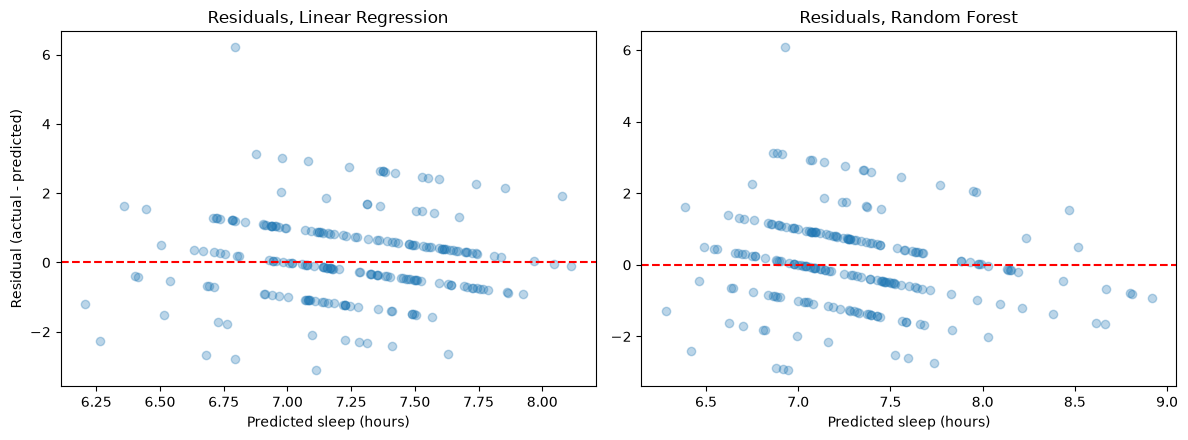

In [ ]:
import matplotlib.pyplot as plt

residuals = y_test_reg - y_pred_lr
residuals_rf = y_test_reg - y_pred_rf_reg

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

ax1.scatter(y_pred_lr, residuals, alpha=0.3)
ax1.axhline(0, color="red", linestyle="--")
ax1.set_xlabel("Predicted sleep (hours)")
ax1.set_ylabel("Residual (actual - predicted)")
ax1.set_title("Residuals, Linear Regression")

ax2.scatter(y_pred_rf_reg, residuals_rf, alpha=0.3)
ax2.axhline(0, color="red", linestyle="--")
ax2.set_xlabel("Predicted sleep (hours)")
ax2.set_title("Residuals, Random Forest")

plt.tight_layout()
plt.show()

As we can see from the residual models (for linear regression and random forest), they both have a low R^2 0.063 and 0.014, which means they only represent a small part of the difference. The MAE is about 0.958 and 0.977 which is slightly better than the Baselines 0.996. Which is vizualised by the residual plot by showing the predictions huddled up in a range around the average.
The plots are showing a repetetive pattern through our results, which indicates a weak correspondence between sleep and our variables.

### Using the evaluation function

In [ ]:
class_models = {
    # "Name shown in the table": the predictions from that model's .predict(X_test)
    "Baseline (most frequent)": y_pred_base,
    "Logistic Regression": y_pred_lg,
    "Decision Tree": y_pred_tree,
    "Random Forest": y_pred_rf,
    "k-NN": y_pred_knn,
}

class_results = []
for name, preds in class_models.items():
    class_results.append(evaluate_classification(name, y_test, preds))

class_df = pd.DataFrame(class_results)
print(class_df.round(3))



reg_models = {
    # "Name shown in the table": the predictions from that model's .predict(X_test) 
    "Baseline (mean)": y_pred_base_reg,
    "Linear Regression": y_pred_lr,
    "Random Forest": y_pred_rf_reg,
}

reg_results = []
for name, preds in reg_models.items():
    reg_results.append(evaluate_regression(name, y_test_reg, preds))

reg_df = pd.DataFrame(reg_results)
print(reg_df.round(3))

                      model  accuracy  precision  recall     f1
0  Baseline (most frequent)     0.770      0.000    0.00  0.000
1       Logistic Regression     0.585      0.296    0.58  0.392
2             Decision Tree     0.765      0.471    0.16  0.239
3             Random Forest     0.779      0.625    0.10  0.172
4                      k-NN     0.760      0.000    0.00  0.000
               model    mae   rmse     r2
0    Baseline (mean)  0.996  1.303 -0.003
1  Linear Regression  0.958  1.259  0.063
2      Random Forest  0.977  1.292  0.014
